# Inspect a model's network

A LAN model's likelihood is a neural network, trained on data from a simulator. It is only as good as the network is accurate for the parameters you care about. `hssm.plotting` has two plots for checking that, built on LANfactory's network inspectors:

- `plot_kde_vs_lan` draws the network's likelihood against kernel density estimates (KDEs) of data simulated at the same parameters.
- `plot_lan_manifold` draws the network's likelihood as a 3D surface while one parameter varies.

Both take an HSSM model with `loglik_kind="approx_differentiable"` and evaluate the ONNX network that model uses, at the same version, so you inspect the network you fit with.

## Run this tutorial

<a href="https://colab.research.google.com/github/lnccbrown/HSSM/blob/main/docs/tutorials/network_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open this notebook in Google Colab"></a>

The plots need the optional `inspect` extra, which installs LANfactory (and with it PyTorch). On Colab, uncomment and run the installation cell below once, then restart the runtime. Locally, install it with `pip install "hssm[inspect]"` or `uv sync --extra inspect`. For local setup, GPU extras, and troubleshooting see the [Installation guide](https://lnccbrown.github.io/HSSM/getting_started/installation/).

In [1]:
# %pip install "hssm[inspect]"

In [2]:
import warnings

import pandas as pd
from IPython.display import HTML
from lanfactory.network_inspectors import PlotConfig

import hssm
from hssm.plotting import plot_kde_vs_lan, plot_lan_manifold

%matplotlib inline
warnings.filterwarnings("ignore")

## Build a LAN model

We simulate data from the angle model, a DDM whose bounds collapse linearly, and build a model that uses its LAN.

In [3]:
true_values = dict(v=0.8, a=1.5, z=0.5, t=0.3, theta=0.2)
data = hssm.simulate_data(model="angle", theta=true_values, size=500, random_state=1)

model = hssm.HSSM(data=data, model="angle", loglik_kind="approx_differentiable")

Model initialized successfully.


## Check the network before fitting

`plot_kde_vs_lan` does not need a fitted model. Give it parameter values, as a dictionary for one set or a DataFrame with one set per row, and it plots, for each set:

- in green, the network's likelihood over response time, with the lower choice drawn at negative response times;
- in grey, `n_reps` KDEs, each of `n_samples` trials simulated with ssm-simulators.

Where the green curve runs through the grey ones, the network matches the simulator.

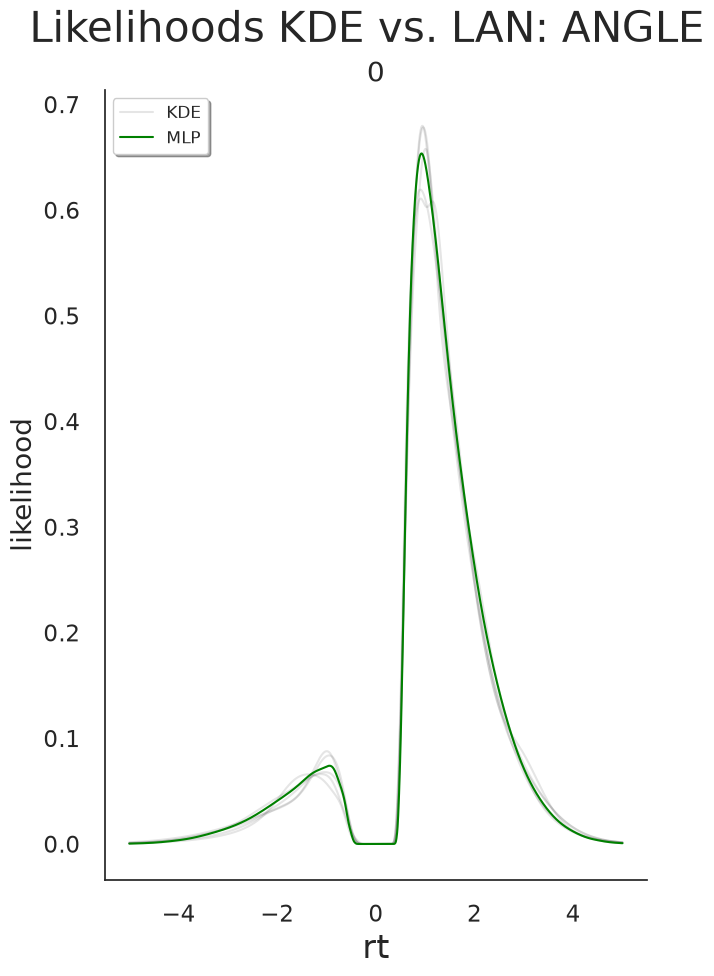

In [4]:
plot_kde_vs_lan(
    model,
    true_values,
    n_samples=2000,
    n_reps=5,
    plot=PlotConfig(cols=1, figsize=(7, 10)),
)

The function returns nothing: LANfactory shows the figure and then closes it. To keep a copy, pass `plot=PlotConfig(save=True, save_dir="figures/")`, which writes `kde_vs_mlp_plot.png` to that folder.

## Check the network where the posterior is

After fitting, the parameters that matter are the ones the posterior puts its mass on. Here we compare the network at the true values and at the posterior mean, one panel each.

In [5]:
idata = model.sample(draws=500, tune=500, chains=4, random_seed=1, progressbar=False)

posterior_mean = idata.posterior.mean(("chain", "draw"))
posterior_mean = {name: float(posterior_mean[name]) for name in true_values}

parameter_sets = pd.DataFrame(
    [true_values, posterior_mean], index=["true", "posterior mean"]
)
parameter_sets

Using default initvals. 



NUTS[numpyro]: [a, z, t, theta, v]


,v,a,z,t,theta
true,0.800000,1.50000,0.500000,0.300000,0.200000
posterior mean,0.645747,1.56531,0.534402,0.278963,0.257359


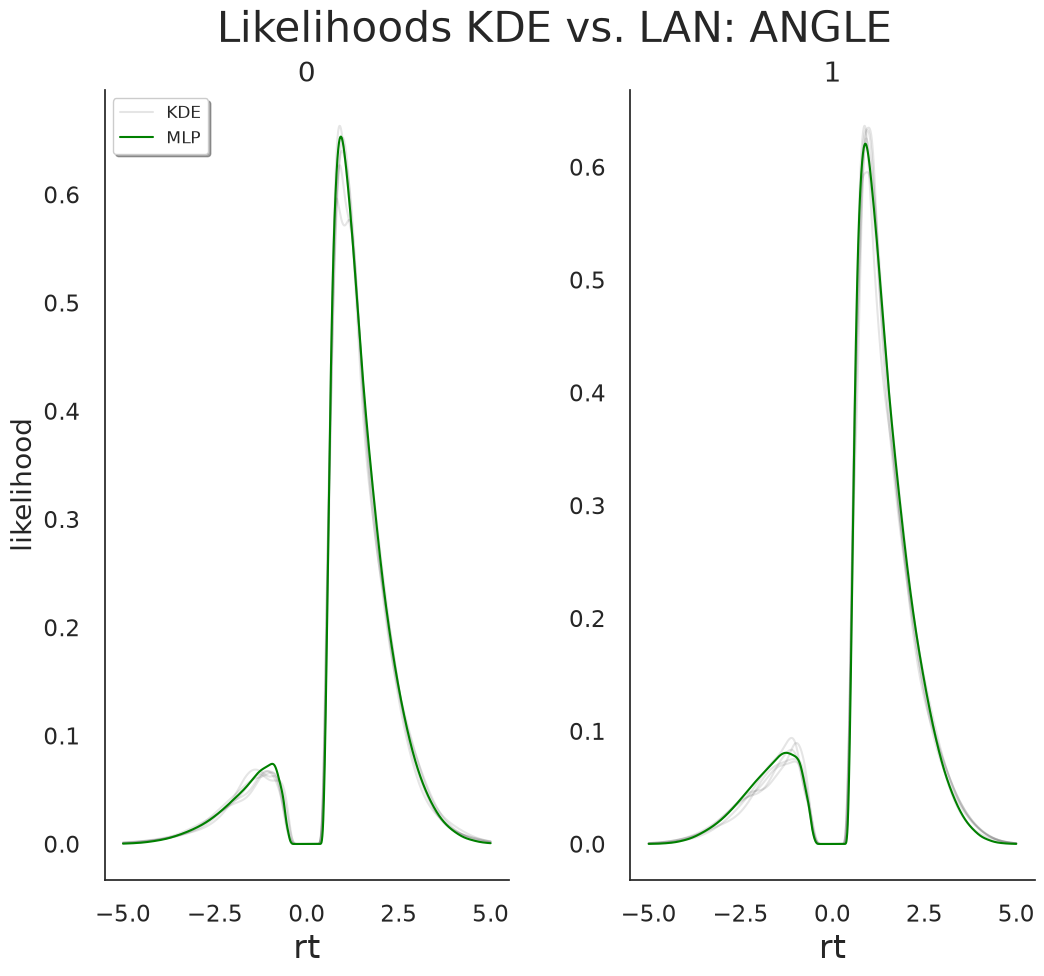

In [6]:
plot_kde_vs_lan(
    model,
    parameter_sets.reset_index(drop=True),
    n_samples=2000,
    n_reps=5,
    plot=PlotConfig(cols=2, figsize=(12, 10)),
)

Panel 0 is the true parameter set and panel 1 the posterior mean. In both, the network follows the KDEs closely.

## See how the likelihood changes with one parameter

`plot_lan_manifold` sweeps one parameter, given in `vary`, and draws the network's likelihood over response time for each value as a surface. The other parameters come from `parameters`; any you leave out take the ssm-simulators defaults. It works for two-choice models and returns a plotly figure.

Here we vary the boundary `a` around the posterior mean. A smooth surface, with the response-time distribution spreading out as `a` grows, is what a well-trained network should show.

In [7]:
fig = plot_lan_manifold(
    model,
    vary={"a": [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]},
    parameters=posterior_mean,
    plot=PlotConfig(show=False),
)
HTML(fig.to_html(include_plotlyjs="cdn", full_html=False))

In a notebook, `fig.show()` also works; the `HTML` call above keeps the figure interactive on this documentation page.

## Options and limits

- **Grid.** `grid=GridSpec(...)` sets the response-time grid: `n_points_2c` and `rt_step_2c` for `plot_kde_vs_lan`, `n_rt_steps` and `max_rt` for `plot_lan_manifold`.
- **Figure.** `plot=PlotConfig(...)` sets the figure size, the number of columns, whether to show it, and whether and where to save it.
- **Which models work.** The model's likelihood must be an ONNX network (`loglik_kind="approx_differentiable"`), and its name, parameters and choices must match an ssm-simulators model, which LANfactory uses to label the network's inputs and to simulate. Other models raise a `ValueError`.
- **Without the extra**, `import hssm` works as usual and the plot functions raise an `ImportError` that names `hssm[inspect]`.